# Day 5: LSTM, data augmentation, and model comparison
Needs everything from Days 1-4 (including models/norm.npz from Day 4).
Only ONE thing to edit: the BASE address in the first code cell.
The augmentation step (cell 3) takes a few minutes the first time and is saved for next time.

In [1]:

BASE = r"C:\Users\Abdul Rehman\Documents\Projects\emotion-recognition"     # <-- change this to your folder

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import tensorflow as tf
from tensorflow.keras import layers, models
from tqdm import tqdm
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score

BASE = Path(BASE)
tf.keras.utils.set_random_seed(42)
EPOCHS = 60

df = pd.read_csv(BASE / "data" / "metadata.csv")
lookup = {f.name: str(f) for f in (BASE / "data" / "ravdess").rglob("*.wav")}
df["path"] = df["path"].map(lambda p: lookup.get(Path(p).name))

X = np.load(BASE / "features" / "X_mfcc.npy")
y = np.load(BASE / "features" / "y.npy")
classes = json.load(open(BASE / "models" / "classes.json"))
norm = np.load(BASE / "models" / "norm.npz")
mean, std = norm["mean"], norm["std"]                   # each (40, 1), from the TRAINING set

tr = (df["actor"] <= 16).values
va = df["actor"].between(17, 20).values
print("Train:", tr.sum(), "| Validation:", va.sum())

Train: 960 | Validation: 240


In [2]:
# 2. Feature settings (must be IDENTICAL to Day 2) and the augmentation functions
SR, DURATION, OFFSET, N_MFCC, HOP_LENGTH, MAX_FRAMES = 22050, 3, 0.5, 40, 512, 130

def mfcc_from_signal(sig):
    m = librosa.feature.mfcc(y=sig, sr=SR, n_mfcc=N_MFCC, hop_length=HOP_LENGTH)
    if m.shape[1] < MAX_FRAMES:
        m = np.pad(m, ((0, 0), (0, MAX_FRAMES - m.shape[1])))
    return m[:, :MAX_FRAMES].astype(np.float32)

def augment(sig, kind, rng):
    if kind == "noise":                                 # add a little random noise
        return sig + 0.01 * np.max(np.abs(sig)) * rng.standard_normal(len(sig))
    if kind == "pitch":                                 # make the voice slightly higher or lower
        steps = 2 if rng.random() < 0.5 else -2
        return librosa.effects.pitch_shift(sig, sr=SR, n_steps=steps)
    if kind == "stretch":                               # make the speech slightly faster or slower
        return librosa.effects.time_stretch(sig, rate=float(rng.choice([0.9, 1.1])))

AUG_KINDS = ["noise", "pitch", "stretch"]

In [3]:
# 3. Create augmented copies of the TRAINING clips only (never validation or test)
aug_x_file = BASE / "features" / "X_aug.npy"
aug_y_file = BASE / "features" / "y_aug.npy"

if aug_x_file.exists() and aug_y_file.exists():
    X_aug, y_aug = np.load(aug_x_file), np.load(aug_y_file)
    print("Loaded saved augmented data:", X_aug.shape)
else:
    rng = np.random.default_rng(42)
    aug_list, aug_labels = [], []
    for i in tqdm(np.where(tr)[0], desc="Augmenting"):
        sig, _ = librosa.load(df.loc[i, "path"], sr=SR, duration=DURATION, offset=OFFSET)
        for kind in AUG_KINDS:
            aug_list.append(mfcc_from_signal(augment(sig, kind, rng)))
            aug_labels.append(y[i])
    X_aug = np.array(aug_list, dtype=np.float32)
    y_aug = np.array(aug_labels)
    np.save(aug_x_file, X_aug)
    np.save(aug_y_file, y_aug)
    print("Saved augmented data:", X_aug.shape)       # expected (2880, 40, 130)

Augmenting:   0%|          | 0/960 [00:00<?, ?it/s]c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\librosa\effects.py:44

Saved augmented data: (2880, 40, 130)


In [4]:
# 4. Model builders and helpers
def prep(X_raw, kind):
    Xn = (X_raw - mean) / std                            # (N, 40, 130)
    if kind == "cnn":
        return Xn[..., np.newaxis]                       # (N, 40, 130, 1)
    return np.transpose(Xn, (0, 2, 1))                   # LSTM wants (N, 130, 40)

def build_cnn(lr=1e-3, dropout=0.4, width=32):
    m = models.Sequential([
        layers.Input(shape=(40, 130, 1)),
        layers.Conv2D(width, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 2, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 4, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout), layers.Dense(64, activation="relu"), layers.Dense(8, activation="softmax")])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def build_lstm(lr=1e-3, dropout=0.3, units=128):
    m = models.Sequential([
        layers.Input(shape=(130, 40)),
        layers.LSTM(units, return_sequences=True), layers.Dropout(dropout),
        layers.LSTM(units // 2), layers.Dropout(dropout),
        layers.Dense(64, activation="relu"), layers.Dense(8, activation="softmax")])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def get_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=20, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=5, min_lr=1e-5)]

RESULTS = BASE / "results.csv"
def save_result(name, acc, f1):
    row = pd.DataFrame([{"model": name, "val_accuracy": round(float(acc), 4), "val_macro_f1": round(float(f1), 4)}])
    if RESULTS.exists():
        old = pd.read_csv(RESULTS)
        old = old[old["model"] != name]
        row = pd.concat([old, row], ignore_index=True)
    row.to_csv(RESULTS, index=False)

In [5]:
# 5. Run the three experiments (change ONE thing at a time, same validation set every time)
experiments = [
    ("LSTM",                "lstm", False),
    ("CNN + augmentation",  "cnn",  True),
    ("LSTM + augmentation", "lstm", True),
]
histories = {}

for name, kind, use_aug in experiments:
    print(f"\n===== {name} =====")
    tf.keras.utils.set_random_seed(42)
    X_train = np.concatenate([X[tr], X_aug]) if use_aug else X[tr]
    y_train = np.concatenate([y[tr], y_aug]) if use_aug else y[tr]
    cw = compute_class_weight("balanced", classes=np.arange(8), y=y_train)
    class_weight = {i: float(w) for i, w in enumerate(cw)}

    model = build_cnn() if kind == "cnn" else build_lstm()
    Xtr, Xva = prep(X_train, kind), prep(X[va], kind)
    h = model.fit(Xtr, y_train, validation_data=(Xva, y[va]), epochs=EPOCHS, batch_size=32,
                  class_weight=class_weight, callbacks=get_callbacks(), verbose=2)
    histories[name] = h.history

    pred = model.predict(Xva, verbose=0).argmax(axis=1)
    acc, f1 = accuracy_score(y[va], pred), f1_score(y[va], pred, average="macro")
    print(f"{name}: validation accuracy {acc:.3f} | macro-F1 {f1:.3f}")
    save_result(name, acc, f1)


===== LSTM =====
Epoch 1/60
30/30 - 10s - 330ms/step - accuracy: 0.1813 - loss: 2.0092 - val_accuracy: 0.2250 - val_loss: 1.8774 - learning_rate: 0.0010
Epoch 2/60
30/30 - 5s - 163ms/step - accuracy: 0.2948 - loss: 1.8163 - val_accuracy: 0.3000 - val_loss: 1.8458 - learning_rate: 0.0010
Epoch 3/60
30/30 - 5s - 153ms/step - accuracy: 0.3719 - loss: 1.6520 - val_accuracy: 0.2542 - val_loss: 2.0570 - learning_rate: 0.0010
Epoch 4/60
30/30 - 5s - 155ms/step - accuracy: 0.4542 - loss: 1.4846 - val_accuracy: 0.2708 - val_loss: 1.9826 - learning_rate: 0.0010
Epoch 5/60
30/30 - 4s - 149ms/step - accuracy: 0.5188 - loss: 1.3374 - val_accuracy: 0.3542 - val_loss: 1.9102 - learning_rate: 0.0010
Epoch 6/60
30/30 - 5s - 150ms/step - accuracy: 0.5135 - loss: 1.2996 - val_accuracy: 0.3083 - val_loss: 2.0596 - learning_rate: 0.0010
Epoch 7/60
30/30 - 5s - 154ms/step - accuracy: 0.5615 - loss: 1.1884 - val_accuracy: 0.3167 - val_loss: 2.2231 - learning_rate: 0.0010
Epoch 8/60
30/30 - 4s - 149ms/step -

              model  val_accuracy  val_macro_f1
       Baseline SVM        0.4708        0.4536
                CNN        0.5333        0.4837
               LSTM        0.4583        0.4519
 CNN + augmentation        0.6458        0.6357
LSTM + augmentation        0.5292        0.5218


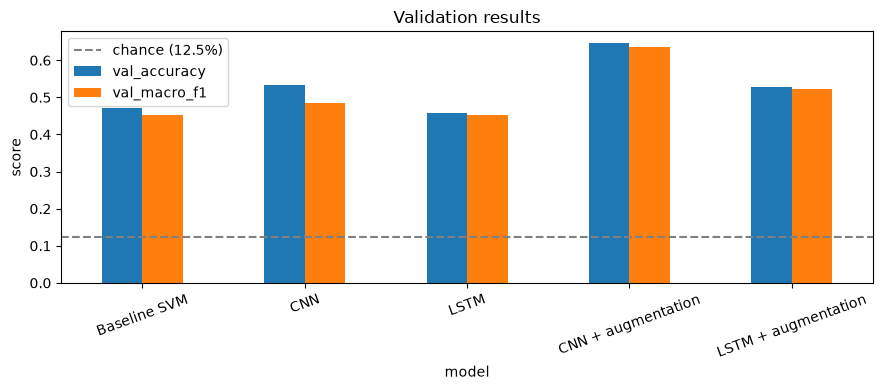

In [6]:
# 6. Comparison table and chart
results = pd.read_csv(RESULTS)
print(results.to_string(index=False))

ax = results.set_index("model")[["val_accuracy", "val_macro_f1"]].plot(kind="bar", figsize=(9, 4), rot=20)
ax.axhline(1 / 8, color="gray", linestyle="--", label="chance (12.5%)")
ax.set_ylabel("score"); ax.set_title("Validation results")
ax.legend(); plt.tight_layout(); plt.show()
# Write 3-4 lines: did augmentation help? Is the CNN or the LSTM better, and why do you think so?